In [2]:
import pandas as pd
import re
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [3]:
df=pd.read_csv("mtsamples.csv")

In [4]:
df=df.dropna(subset=['transcription', 'medical_specialty'])

In [5]:
top_classes = df["medical_specialty"].value_counts().head(5).index
df = df[df["medical_specialty"].isin(top_classes)]

In [6]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

In [7]:
df["clean_text"] = df["transcription"].apply(clean_text)

In [8]:
X = df["clean_text"]
y = df["medical_specialty"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# TF-IDF feature extraction
vectorizer = TfidfVectorizer(
    stop_words="english",
    max_features=5000
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

In [9]:
model = LinearSVC()
model.fit(X_train_tfidf, y_train)

# Prediction
y_pred = model.predict(X_test_tfidf)

# Accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Total samples:", len(df))
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Feature size:", X_train_tfidf.shape[1])


Total samples: 2603
Training samples: 2082
Testing samples: 521
Feature size: 5000


In [10]:
print("\nAccuracy:", round(accuracy * 100, 2), "%")



Accuracy: 54.32 %



Classification Report:
                             precision    recall  f1-score   support

 Cardiovascular / Pulmonary       0.19      0.16      0.17        74
 Consult - History and Phy.       0.82      0.82      0.82       103
                 Orthopedic       0.18      0.18      0.18        71
                  Radiology       0.46      0.49      0.47        55
                    Surgery       0.66      0.67      0.67       218

                   accuracy                           0.54       521
                  macro avg       0.46      0.47      0.46       521
               weighted avg       0.54      0.54      0.54       521



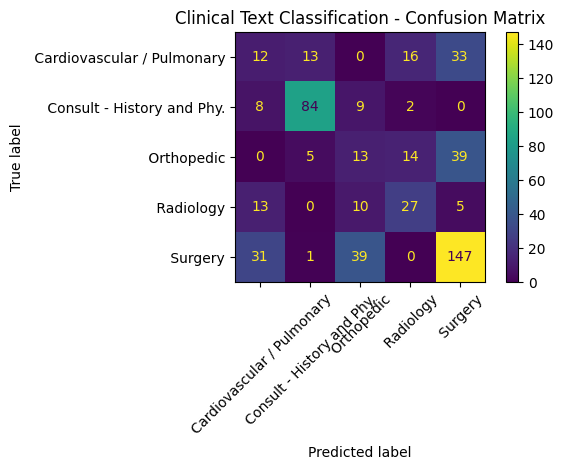

In [11]:
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=model.classes_
)

disp.plot(xticks_rotation=45)
plt.title("Clinical Text Classification - Confusion Matrix")
plt.tight_layout()
plt.show()